In [1]:
import warnings
warnings.filterwarnings('ignore')

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBClassifier
from sklearn.metrics import classification_report, average_precision_score, precision_recall_curve, ConfusionMatrixDisplay
from sklearn.preprocessing import OneHotEncoder

In [2]:
# Data Collection
df_train = pd.read_csv("fraudTrain.csv")
df_test = pd.read_csv("fraudTest.csv")

def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    km = 6371 * c
    return km

def preprocess_data(df):
    """Applies feature engineering to a given dataframe."""
    # Drop unnecessary columns
    df = df.drop(columns=['Unnamed: 0', 'cc_num', 'merchant', 'first', 'last', 
                          'street', 'city', 'state', 'zip', 'city_pop', 'job', 
                          'trans_num', 'unix_time'])
    
    # Datetime features
    df['trans_date_trans_time'] = pd.to_datetime(df['trans_date_trans_time'])
    df['dob'] = pd.to_datetime(df['dob'])
    
    df['trans_hour'] = df['trans_date_trans_time'].dt.hour
    df['trans_day'] = df['trans_date_trans_time'].dt.day
    df['trans_month'] = df['trans_date_trans_time'].dt.month
    df['age'] = (df['trans_date_trans_time'] - df['dob']).dt.days // 365
    
    # Distance feature
    df["distance_km"] = haversine(df["lat"], df["long"], df["merch_lat"], df["merch_long"])
    
    # Drop original datetime columns
    df = df.drop(columns=['trans_date_trans_time', 'dob'])
    
    return df

# Apply preprocessing independently to prevent temporal data leakage
train_processed = preprocess_data(df_train)
test_processed = preprocess_data(df_test)

In [3]:
# Separate features and target
X_train = train_processed.drop(columns=["is_fraud"])
y_train = train_processed["is_fraud"]

X_test = test_processed.drop(columns=["is_fraud"])
y_test = test_processed["is_fraud"]

# Categorical Feature Encoding
cat_cols = ["category", "gender"]
encoder = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')

# Fit ONLY on training data to prevent leakage, transform both
encoded_train_cats = pd.DataFrame(
    encoder.fit_transform(X_train[cat_cols]), 
    columns=encoder.get_feature_names_out(cat_cols),
    index=X_train.index
)

encoded_test_cats = pd.DataFrame(
    encoder.transform(X_test[cat_cols]), 
    columns=encoder.get_feature_names_out(cat_cols),
    index=X_test.index
)

# Drop original categorical columns and concatenate encoded ones
X_train = X_train.drop(columns=cat_cols)
X_train = pd.concat([X_train, encoded_train_cats], axis=1)

X_test = X_test.drop(columns=cat_cols)
X_test = pd.concat([X_test, encoded_test_cats], axis=1)


Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.99      1.00    553574
           1       0.37      0.91      0.52      2145

    accuracy                           0.99    555719
   macro avg       0.68      0.95      0.76    555719
weighted avg       1.00      0.99      0.99    555719

PR-AUC: 0.8523



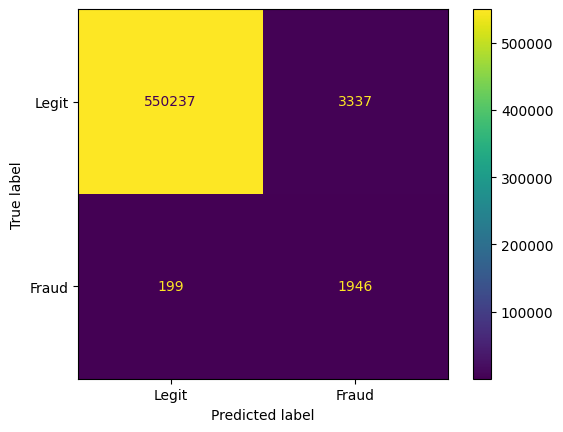

In [4]:
# Model Training
# Calculate scale_pos_weight dynamically based on training data only
scale_weight = (len(y_train) - sum(y_train)) / sum(y_train)

model = XGBClassifier(scale_pos_weight=scale_weight, random_state=42)
model.fit(X_train, y_train)

# Model Evaluation
y_pred = model.predict(X_test)
print("\nClassification Report:\n", classification_report(y_test, y_pred))

y_pred_proba = model.predict_proba(X_test)[:, 1]
pr_auc = average_precision_score(y_test, y_pred_proba)
print(f"PR-AUC: {pr_auc:.4f}\n")

# Confusion Matrix
disp = ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=["Legit", "Fraud"])
plt.show()

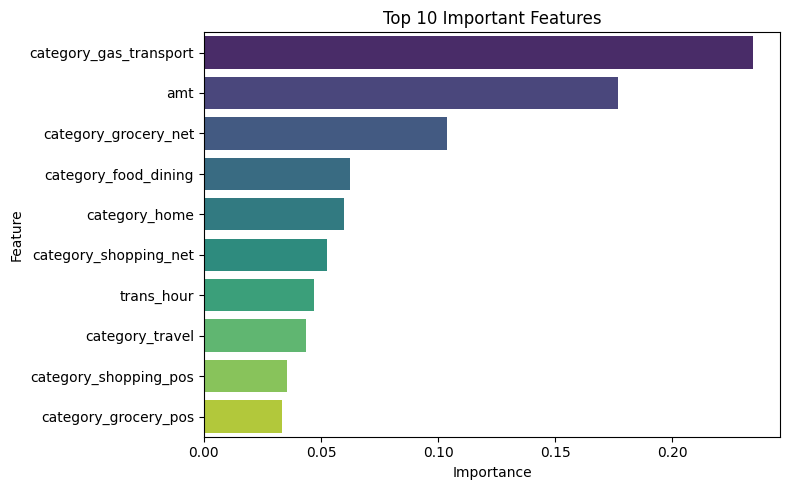

In [5]:
# Feature Importance
importance = pd.DataFrame({
    "Feature": X_train.columns, 
    "Importance": model.feature_importances_
})
importance = importance.sort_values(by="Importance", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=importance.head(10), x="Importance", y="Feature", palette="viridis")
plt.title("Top 10 Important Features")
plt.tight_layout()
plt.show()

In [6]:
# Model Serialization
joblib.dump(model, "Credit_Card_Fraud_Detection.pkl")
print("Model saved successfully.")

Model saved successfully.
